# Notebook A – Hotel booking cancellation: tuned 5-fold cross-validation, duplicate leakage and SHAP
Leakage-free pipeline (duplicates removed; clipping, scaling and SMOTE fitted on training data only). Every model's hyperparameters are chosen **inside each training fold** by random search on an inner validation set, so the test fold is never used for tuning.

In [3]:
# Cell 0 (Colab only): install libraries, then upload hotel_bookings.csv using the Files panel
!pip install -q xgboost lightgbm imbalanced-learn statsmodels shap


## 1. Data preparation

In [2]:
# Cell 1: Imports and settings
import os
import time
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import xgboost as xgb
import lightgbm as lgb
import shap
from scipy.stats import friedmanchisquare, spearmanr
from statsmodels.stats.contingency_tables import mcnemar
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve, classification_report)
from imblearn.over_sampling import SMOTE
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import (Input, Conv1D, Dense, Dropout, Flatten,
                                     BatchNormalization, Concatenate, Reshape)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

warnings.filterwarnings('ignore')
SEED = 42
N_FOLDS = 5
EPOCHS = 50
N_CONFIGS_GBM = 15      # random-search configurations per boosting model
N_CONFIGS_DL = 6        # random-search configurations per neural network
DATA_PATH = 'hotel_bookings.csv'
OUT_DIR = 'results_A'
os.makedirs(OUT_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
GPU = len(tf.config.list_physical_devices('GPU')) > 0
XGB_DEVICE = 'cuda' if GPU else 'cpu'
print('TensorFlow', tf.__version__, '| XGBoost', xgb.__version__, '| LightGBM', lgb.__version__, '| SHAP', shap.__version__)
print('GPU available:', GPU, '| XGBoost device:', XGB_DEVICE)


TensorFlow 2.21.0 | XGBoost 3.4.1 | LightGBM 4.6.0 | SHAP 0.52.0
GPU available: True | XGBoost device: cuda


In [4]:
# Cell 2: Load data and remove exact duplicates
df_raw = pd.read_csv(DATA_PATH)
n_raw = len(df_raw)
n_dup = df_raw.duplicated().sum()
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f'Raw records:         {n_raw:,}')
print(f'Exact duplicates:    {n_dup:,} ({n_dup / n_raw:.1%})')
print(f'Records after dedup: {len(df):,}')


Raw records:         119,390
Exact duplicates:    31,994 (26.8%)
Records after dedup: 87,396


In [5]:
# Cell 3: Remove leakage columns, handle missing values, engineer features
leak_cols = ['reservation_status', 'reservation_status_date', 'assigned_room_type',
             'booking_changes', 'agent', 'company']
df = df.drop(columns=leak_cols)
df['children'] = df['children'].fillna(0)
df['country'] = df['country'].fillna('Unknown')
country_counts = df['country'].value_counts()
rare_countries = country_counts[country_counts < 100].index
df.loc[df['country'].isin(rare_countries), 'country'] = 'Other'
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['was_waitlisted'] = (df['days_in_waiting_list'] > 0).astype(int)
df['is_family'] = ((df['children'] + df['babies']) > 0).astype(int)
df = df[df['total_guests'] > 0].reset_index(drop=True)
arrival_date = pd.to_datetime(df['arrival_date_year'].astype(str) + '-' + df['arrival_date_month'] + '-' +
                              df['arrival_date_day_of_month'].astype(str), format='%Y-%B-%d')
print('Shape after cleaning:', df.shape)


Shape after cleaning: (87230, 30)


In [6]:
# Cell 4: Encode categorical features
cat_cols = ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
            'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type']
y = df['is_canceled'].values
X = df.drop(columns=['is_canceled'])
num_cols = [c for c in X.columns if c not in cat_cols]
X = pd.get_dummies(X, columns=cat_cols, drop_first=False, dtype=float).astype('float32')
feature_names = X.columns.tolist()
print('Total features after one-hot encoding:', X.shape[1], '| Class counts:', np.bincount(y))


Total features after one-hot encoding: 105 | Class counts: [63221 24009]


In [7]:
# Cell 5: Random-search configurations (drawn once, the same for every fold)
rng = np.random.RandomState(SEED)
lr_grid = [0.01, 0.1, 1.0, 10.0]
xgb_configs = [{'max_depth': int(rng.choice([4, 6, 8, 10])), 'learning_rate': float(rng.choice([0.03, 0.05, 0.1])),
                'subsample': float(rng.choice([0.7, 0.8, 1.0])), 'colsample_bytree': float(rng.choice([0.6, 0.8, 1.0])),
                'min_child_weight': int(rng.choice([1, 3, 5])), 'reg_lambda': float(rng.choice([0.5, 1.0, 5.0]))}
               for _ in range(N_CONFIGS_GBM)]
lgb_configs = [{'num_leaves': int(rng.choice([31, 63, 127, 255])), 'learning_rate': float(rng.choice([0.03, 0.05, 0.1])),
                'min_child_samples': int(rng.choice([10, 20, 50])), 'colsample_bytree': float(rng.choice([0.6, 0.8, 1.0])),
                'subsample': float(rng.choice([0.7, 0.8, 1.0])), 'reg_lambda': float(rng.choice([0.0, 1.0, 5.0]))}
               for _ in range(N_CONFIGS_GBM)]
dl_configs = [{'learning_rate': float(rng.choice([1e-3, 5e-4, 2e-4])), 'dropout': float(rng.choice([0.2, 0.3, 0.4])),
               'width': float(rng.choice([0.5, 1.0])), 'batch_size': int(rng.choice([256, 512]))}
              for _ in range(N_CONFIGS_DL)]
pd.DataFrame(xgb_configs).to_csv(f'{OUT_DIR}/search_space_xgboost.csv', index_label='config')
pd.DataFrame(lgb_configs).to_csv(f'{OUT_DIR}/search_space_lightgbm.csv', index_label='config')
pd.DataFrame(dl_configs).to_csv(f'{OUT_DIR}/search_space_neural.csv', index_label='config')
print(f'{len(lr_grid)} logistic regression values, {N_CONFIGS_GBM} XGBoost, {N_CONFIGS_GBM} LightGBM and {N_CONFIGS_DL} neural-network configurations')


4 logistic regression values, 15 XGBoost, 15 LightGBM and 6 neural-network configurations


In [8]:
# Cell 6: Prepare the 5 folds (identical for every model)
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
split_names, split_train_X, split_train_y, split_val_X, split_val_y = [], [], [], [], []
split_test_X, split_test_y, split_test_idx = [], [], []
for fold, (tr_idx, te_idx) in enumerate(skf.split(X.values, y), start=1):
    X_tr_df = X.iloc[tr_idx].copy()
    X_te_df = X.iloc[te_idx].copy()
    y_tr, y_te = y[tr_idx], y[te_idx]
    upper = X_tr_df[num_cols].quantile(0.99)
    X_tr_df[num_cols] = X_tr_df[num_cols].clip(upper=upper, axis=1)
    X_te_df[num_cols] = X_te_df[num_cols].clip(upper=upper, axis=1)
    # inner validation split: used for early stopping AND for choosing hyperparameters
    X_in_df, X_val_df, y_in, y_val = train_test_split(X_tr_df, y_tr, test_size=0.1, stratify=y_tr, random_state=SEED)
    scaler = MinMaxScaler()
    X_in_df[num_cols] = scaler.fit_transform(X_in_df[num_cols])
    X_val_df[num_cols] = scaler.transform(X_val_df[num_cols])
    X_te_df[num_cols] = scaler.transform(X_te_df[num_cols])
    X_sm, y_sm = SMOTE(random_state=SEED).fit_resample(X_in_df.values, y_in)
    split_names.append(f'Fold {fold}')
    split_train_X.append(X_sm.astype('float32'))
    split_train_y.append(y_sm)
    split_val_X.append(X_val_df.values.astype('float32'))
    split_val_y.append(y_val)
    split_test_X.append(X_te_df.values.astype('float32'))
    split_test_y.append(y_te)
    split_test_idx.append(te_idx)
    print(f'Fold {fold}: train after SMOTE = {len(y_sm):,} | val = {len(y_val):,} | test = {len(y_te):,}')


Fold 1: train after SMOTE = 91,036 | val = 6,979 | test = 17,446
Fold 2: train after SMOTE = 91,038 | val = 6,979 | test = 17,446
Fold 3: train after SMOTE = 91,038 | val = 6,979 | test = 17,446
Fold 4: train after SMOTE = 91,038 | val = 6,979 | test = 17,446
Fold 5: train after SMOTE = 91,038 | val = 6,979 | test = 17,446


In [9]:
# Cell 7: Shared containers
model_names = ['Logistic Regression', '1D CNN', 'DNN', 'CNN+DNN Hybrid', 'XGBoost', 'LightGBM']
N_SPLITS = len(split_names)
n_feat = split_train_X[0].shape[1]
oof_proba = {m: np.full(len(y), np.nan) for m in model_names}
results_rows = []
histories = {}


## 2. Logistic Regression

In [10]:
# Cell 8: Train Logistic Regression (hyperparameter search inside each fold)
m = 'Logistic Regression'
results_rows = [r for r in results_rows if r['Model'] != m]
for s in range(N_SPLITS):
    best_auc, best_p, best_cfg, best_time, search_time = -1.0, None, None, 0.0, 0.0
    for ci, C in enumerate(lr_grid):
        t0 = time.time()
        lr_model = LogisticRegression(C=C, max_iter=2000, random_state=SEED)
        lr_model.fit(split_train_X[s], split_train_y[s])
        fit_time = time.time() - t0
        search_time += fit_time
        val_auc = roc_auc_score(split_val_y[s], lr_model.predict_proba(split_val_X[s])[:, 1])
        if val_auc > best_auc:
            best_auc, best_cfg, best_time = val_auc, ci, fit_time
            best_p = lr_model.predict_proba(split_test_X[s])[:, 1]
    pred = (best_p >= 0.5).astype(int)
    yt = split_test_y[s]
    oof_proba[m][split_test_idx[s]] = best_p
    results_rows.append({'Split': split_names[s], 'Model': m, 'Accuracy': accuracy_score(yt, pred),
                         'Precision': precision_score(yt, pred), 'Recall': recall_score(yt, pred),
                         'F1': f1_score(yt, pred), 'ROC-AUC': roc_auc_score(yt, best_p),
                         'PR-AUC': average_precision_score(yt, best_p), 'Fit time of chosen config (s)': best_time,
                         'Search time (s)': search_time, 'Chosen config': best_cfg, 'Validation ROC-AUC': best_auc})
    print(f'{split_names[s]}: config={best_cfg}  val AUC={best_auc:.4f}  test Acc={results_rows[-1]["Accuracy"]:.4f}  '
          f'F1={results_rows[-1]["F1"]:.4f}  AUC={results_rows[-1]["ROC-AUC"]:.4f}  search={search_time:.0f}s')


Fold 1: config=3  val AUC=0.8427  test Acc=0.7457  F1=0.6236  AUC=0.8366  search=12s
Fold 2: config=2  val AUC=0.8379  test Acc=0.7487  F1=0.6257  AUC=0.8360  search=14s
Fold 3: config=2  val AUC=0.8340  test Acc=0.7483  F1=0.6249  AUC=0.8337  search=15s
Fold 4: config=3  val AUC=0.8409  test Acc=0.7488  F1=0.6241  AUC=0.8374  search=12s
Fold 5: config=2  val AUC=0.8442  test Acc=0.7507  F1=0.6283  AUC=0.8376  search=9s


===== Logistic Regression: results per split =====
 Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Fit time of chosen config (s)  Search time (s)  Chosen config  Validation ROC-AUC
Fold 1    0.7457     0.5260  0.7657 0.6236   0.8366  0.6734                         4.5797          12.0779              3              0.8427
Fold 2    0.7487     0.5302  0.7630 0.6257   0.8360  0.6650                         3.4655          13.7179              2              0.8379
Fold 3    0.7483     0.5298  0.7616 0.6249   0.8337  0.6621                         3.9695          15.3809              2              0.8340
Fold 4    0.7488     0.5306  0.7574 0.6241   0.8374  0.6707                         2.8683          12.3277              3              0.8409
Fold 5    0.7507     0.5328  0.7655 0.6283   0.8376  0.6682                         2.0983           9.0000              2              0.8442

Mean ± std:
  Accuracy   0.7484 ± 0.0018
  Precision  0.5299 ± 0.0024
  Recall     0.7626 

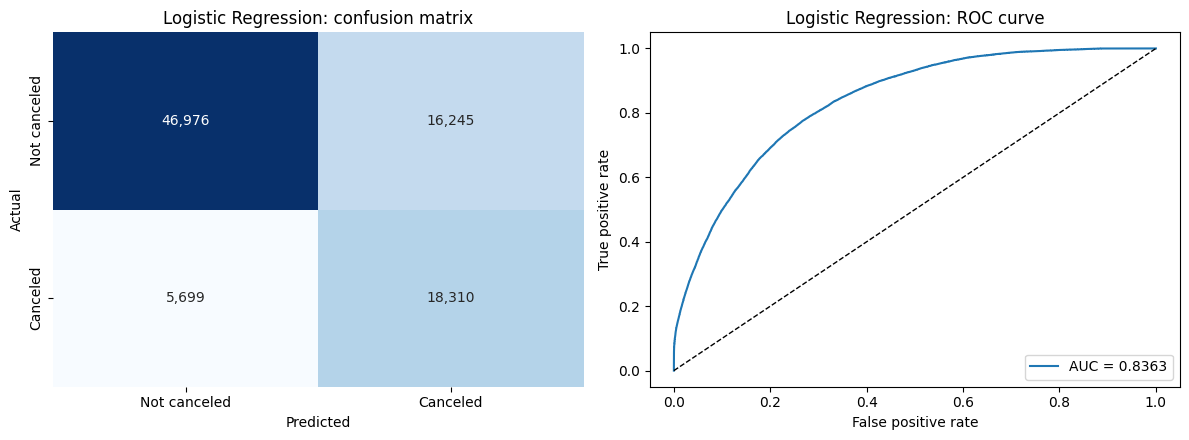

In [11]:
# Cell 9: Evaluate Logistic Regression
m = 'Logistic Regression'
tag = 'logreg'
res = pd.DataFrame([r for r in results_rows if r['Model'] == m]).drop(columns='Model')
print(f'===== {m}: results per split =====')
print(res.round(4).to_string(index=False))
print('\nMean ± std:')
for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    print(f'  {col:<10} {res[col].mean():.4f} ± {res[col].std():.4f}')
mask = ~np.isnan(oof_proba[m])
pred = (oof_proba[m][mask] >= 0.5).astype(int)
print(f'\n===== {m}: classification report (pooled test predictions) =====')
print(classification_report(y[mask], pred, target_names=['Not canceled', 'Canceled'], digits=4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax_cm, ax_roc = axes[0], axes[1]
cm = confusion_matrix(y[mask], pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax_cm,
            xticklabels=['Not canceled', 'Canceled'], yticklabels=['Not canceled', 'Canceled'])
ax_cm.set_title(f'{m}: confusion matrix')
ax_cm.set_xlabel('Predicted')
ax_cm.set_ylabel('Actual')
fpr, tpr, _ = roc_curve(y[mask], oof_proba[m][mask])
ax_roc.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y[mask], oof_proba[m][mask]):.4f}')
ax_roc.plot([0, 1], [0, 1], 'k--', lw=1)
ax_roc.set_title(f'{m}: ROC curve')
ax_roc.set_xlabel('False positive rate')
ax_roc.set_ylabel('True positive rate')
ax_roc.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/eval_{tag}.png', dpi=300)
plt.show()


## 3. 1D CNN

In [12]:
# Cell 10: Train 1D CNN (hyperparameter search inside each fold)
m = '1D CNN'
results_rows = [r for r in results_rows if r['Model'] != m]
histories[m] = []
for s in range(N_SPLITS):
    best_auc, best_p, best_cfg, best_time, search_time, best_hist = -1.0, None, None, 0.0, 0.0, None
    for ci, c in enumerate(dl_configs):
        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED + s)
        w, dr = c['width'], c['dropout']
        net = Sequential([
            Input(shape=(n_feat, 1)),
            Conv1D(int(64 * w), kernel_size=3, activation='relu', padding='same', kernel_regularizer=l2(1e-4)),
            BatchNormalization(), Dropout(dr),
            Conv1D(int(128 * w), kernel_size=3, activation='relu', padding='same', kernel_regularizer=l2(1e-4)),
            BatchNormalization(), Dropout(dr),
            Flatten(),
            Dense(int(64 * w), activation='relu', kernel_regularizer=l2(1e-4)), Dropout(dr),
            Dense(1, activation='sigmoid')
        ])
        net.compile(optimizer=Adam(learning_rate=c['learning_rate']), loss='binary_crossentropy', metrics=['accuracy'])
        t0 = time.time()
        h = net.fit(split_train_X[s][..., None], split_train_y[s], validation_data=(split_val_X[s][..., None], split_val_y[s]),
                    epochs=EPOCHS, batch_size=c['batch_size'], verbose=0,
                    callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
                               ReduceLROnPlateau(monitor='val_loss', patience=2, factor=0.5)])
        fit_time = time.time() - t0
        search_time += fit_time
        val_auc = roc_auc_score(split_val_y[s], net.predict(split_val_X[s][..., None], batch_size=2048, verbose=0).ravel())
        if val_auc > best_auc:
            best_auc, best_cfg, best_time, best_hist = val_auc, ci, fit_time, h.history
            best_p = net.predict(split_test_X[s][..., None], batch_size=2048, verbose=0).ravel()
            if s == 0:
                net.save(f'{OUT_DIR}/cnn_fold1_best.keras')
    histories[m].append(best_hist)
    pred = (best_p >= 0.5).astype(int)
    yt = split_test_y[s]
    oof_proba[m][split_test_idx[s]] = best_p
    results_rows.append({'Split': split_names[s], 'Model': m, 'Accuracy': accuracy_score(yt, pred),
                         'Precision': precision_score(yt, pred), 'Recall': recall_score(yt, pred),
                         'F1': f1_score(yt, pred), 'ROC-AUC': roc_auc_score(yt, best_p),
                         'PR-AUC': average_precision_score(yt, best_p), 'Fit time of chosen config (s)': best_time,
                         'Search time (s)': search_time, 'Chosen config': best_cfg, 'Validation ROC-AUC': best_auc})
    print(f'{split_names[s]}: config={best_cfg}  val AUC={best_auc:.4f}  test Acc={results_rows[-1]["Accuracy"]:.4f}  '
          f'F1={results_rows[-1]["F1"]:.4f}  AUC={results_rows[-1]["ROC-AUC"]:.4f}  search={search_time:.0f}s')


Fold 1: config=4  val AUC=0.8941  test Acc=0.8195  F1=0.6909  AUC=0.8909  search=313s
Fold 2: config=4  val AUC=0.8873  test Acc=0.8236  F1=0.6709  AUC=0.8862  search=219s
Fold 3: config=2  val AUC=0.8898  test Acc=0.8139  F1=0.6785  AUC=0.8815  search=254s
Fold 4: config=2  val AUC=0.8911  test Acc=0.8104  F1=0.6836  AUC=0.8864  search=261s
Fold 5: config=2  val AUC=0.8958  test Acc=0.8112  F1=0.6894  AUC=0.8882  search=282s


===== 1D CNN: results per split =====
 Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Fit time of chosen config (s)  Search time (s)  Chosen config  Validation ROC-AUC
Fold 1    0.8195     0.6534  0.7330 0.6909   0.8909  0.7643                        89.4504         312.5457              4              0.8941
Fold 2    0.8236     0.6897  0.6531 0.6709   0.8862  0.7488                        52.1442         218.7891              4              0.8873
Fold 3    0.8139     0.6467  0.7137 0.6785   0.8815  0.7415                        73.0463         253.7843              2              0.8898
Fold 4    0.8104     0.6323  0.7441 0.6836   0.8864  0.7522                        81.0997         260.6408              2              0.8911
Fold 5    0.8112     0.6301  0.7609 0.6894   0.8882  0.7508                        97.2908         282.2851              2              0.8958

Mean ± std:
  Accuracy   0.8157 ± 0.0057
  Precision  0.6504 ± 0.0240
  Recall     0.7209 ± 0.0417
  F1

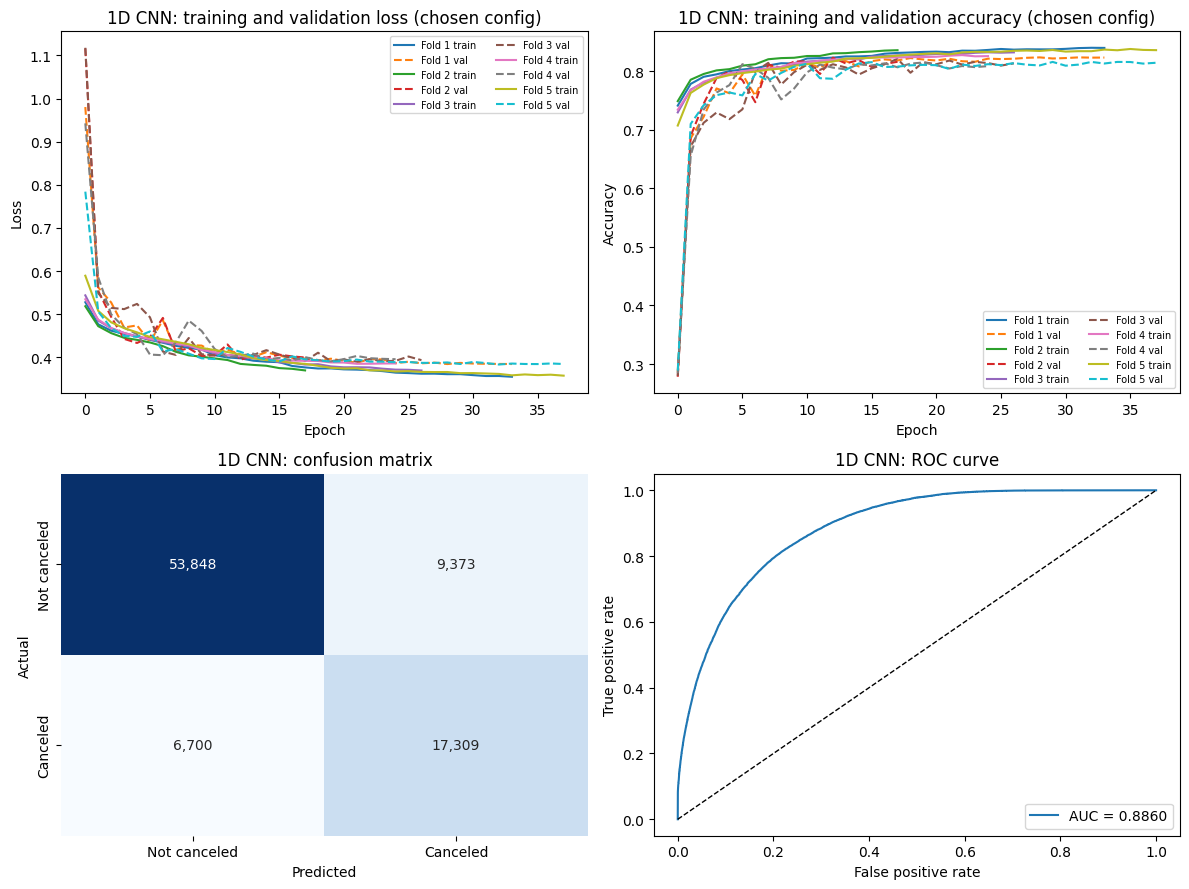

In [13]:
# Cell 11: Evaluate 1D CNN
m = '1D CNN'
tag = 'cnn'
res = pd.DataFrame([r for r in results_rows if r['Model'] == m]).drop(columns='Model')
print(f'===== {m}: results per split =====')
print(res.round(4).to_string(index=False))
print('\nMean ± std:')
for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    print(f'  {col:<10} {res[col].mean():.4f} ± {res[col].std():.4f}')
mask = ~np.isnan(oof_proba[m])
pred = (oof_proba[m][mask] >= 0.5).astype(int)
print(f'\n===== {m}: classification report (pooled test predictions) =====')
print(classification_report(y[mask], pred, target_names=['Not canceled', 'Canceled'], digits=4))
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for k, hist in enumerate(histories[m]):
    axes[0, 0].plot(hist['loss'], label=f'{split_names[k]} train')
    axes[0, 0].plot(hist['val_loss'], '--', label=f'{split_names[k]} val')
    axes[0, 1].plot(hist['accuracy'], label=f'{split_names[k]} train')
    axes[0, 1].plot(hist['val_accuracy'], '--', label=f'{split_names[k]} val')
axes[0, 0].set_title(f'{m}: training and validation loss (chosen config)')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend(fontsize=7, ncol=2)
axes[0, 1].set_title(f'{m}: training and validation accuracy (chosen config)')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend(fontsize=7, ncol=2)
ax_cm, ax_roc = axes[1, 0], axes[1, 1]
cm = confusion_matrix(y[mask], pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax_cm,
            xticklabels=['Not canceled', 'Canceled'], yticklabels=['Not canceled', 'Canceled'])
ax_cm.set_title(f'{m}: confusion matrix')
ax_cm.set_xlabel('Predicted')
ax_cm.set_ylabel('Actual')
fpr, tpr, _ = roc_curve(y[mask], oof_proba[m][mask])
ax_roc.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y[mask], oof_proba[m][mask]):.4f}')
ax_roc.plot([0, 1], [0, 1], 'k--', lw=1)
ax_roc.set_title(f'{m}: ROC curve')
ax_roc.set_xlabel('False positive rate')
ax_roc.set_ylabel('True positive rate')
ax_roc.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/eval_{tag}.png', dpi=300)
plt.show()


## 4. DNN

In [14]:
# Cell 12: Train DNN (hyperparameter search inside each fold)
m = 'DNN'
results_rows = [r for r in results_rows if r['Model'] != m]
histories[m] = []
for s in range(N_SPLITS):
    best_auc, best_p, best_cfg, best_time, search_time, best_hist = -1.0, None, None, 0.0, 0.0, None
    for ci, c in enumerate(dl_configs):
        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED + s)
        w, dr = c['width'], c['dropout']
        net = Sequential([
            Input(shape=(n_feat,)),
            Dense(int(512 * w), activation='relu', kernel_regularizer=l2(1e-4)), BatchNormalization(), Dropout(dr),
            Dense(int(256 * w), activation='relu', kernel_regularizer=l2(1e-4)), BatchNormalization(), Dropout(dr),
            Dense(int(128 * w), activation='relu', kernel_regularizer=l2(1e-4)), BatchNormalization(), Dropout(dr),
            Dense(int(64 * w), activation='relu', kernel_regularizer=l2(1e-4)), BatchNormalization(),
            Dense(1, activation='sigmoid')
        ])
        net.compile(optimizer=Adam(learning_rate=c['learning_rate']), loss='binary_crossentropy', metrics=['accuracy'])
        t0 = time.time()
        h = net.fit(split_train_X[s], split_train_y[s], validation_data=(split_val_X[s], split_val_y[s]),
                    epochs=EPOCHS, batch_size=c['batch_size'], verbose=0,
                    callbacks=[EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True),
                               ReduceLROnPlateau(monitor='val_loss', patience=3, factor=0.5)])
        fit_time = time.time() - t0
        search_time += fit_time
        val_auc = roc_auc_score(split_val_y[s], net.predict(split_val_X[s], batch_size=2048, verbose=0).ravel())
        if val_auc > best_auc:
            best_auc, best_cfg, best_time, best_hist = val_auc, ci, fit_time, h.history
            best_p = net.predict(split_test_X[s], batch_size=2048, verbose=0).ravel()
            if s == 0:
                net.save(f'{OUT_DIR}/dnn_fold1_best.keras')
    histories[m].append(best_hist)
    pred = (best_p >= 0.5).astype(int)
    yt = split_test_y[s]
    oof_proba[m][split_test_idx[s]] = best_p
    results_rows.append({'Split': split_names[s], 'Model': m, 'Accuracy': accuracy_score(yt, pred),
                         'Precision': precision_score(yt, pred), 'Recall': recall_score(yt, pred),
                         'F1': f1_score(yt, pred), 'ROC-AUC': roc_auc_score(yt, best_p),
                         'PR-AUC': average_precision_score(yt, best_p), 'Fit time of chosen config (s)': best_time,
                         'Search time (s)': search_time, 'Chosen config': best_cfg, 'Validation ROC-AUC': best_auc})
    print(f'{split_names[s]}: config={best_cfg}  val AUC={best_auc:.4f}  test Acc={results_rows[-1]["Accuracy"]:.4f}  '
          f'F1={results_rows[-1]["F1"]:.4f}  AUC={results_rows[-1]["ROC-AUC"]:.4f}  search={search_time:.0f}s')


Fold 1: config=4  val AUC=0.8971  test Acc=0.8118  F1=0.7001  AUC=0.8953  search=347s
Fold 2: config=2  val AUC=0.8913  test Acc=0.8008  F1=0.6873  AUC=0.8891  search=280s
Fold 3: config=4  val AUC=0.8968  test Acc=0.8035  F1=0.6886  AUC=0.8883  search=316s
Fold 4: config=3  val AUC=0.8935  test Acc=0.8056  F1=0.6924  AUC=0.8907  search=244s
Fold 5: config=2  val AUC=0.8953  test Acc=0.7988  F1=0.6826  AUC=0.8860  search=243s


===== DNN: results per split =====
 Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Fit time of chosen config (s)  Search time (s)  Chosen config  Validation ROC-AUC
Fold 1    0.8118     0.6234  0.7984 0.7001   0.8953  0.7754                        53.9697         347.3925              4              0.8971
Fold 2    0.8008     0.6051  0.7953 0.6873   0.8891  0.7613                        45.3920         280.2841              2              0.8913
Fold 3    0.8035     0.6107  0.7895 0.6886   0.8883  0.7624                        63.5495         316.4607              4              0.8968
Fold 4    0.8056     0.6134  0.7947 0.6924   0.8907  0.7647                        61.8489         243.7691              3              0.8935
Fold 5    0.7988     0.6031  0.7863 0.6826   0.8860  0.7530                        42.5202         243.0757              2              0.8953

Mean ± std:
  Accuracy   0.8041 ± 0.0050
  Precision  0.6111 ± 0.0080
  Recall     0.7928 ± 0.0048
  F1   

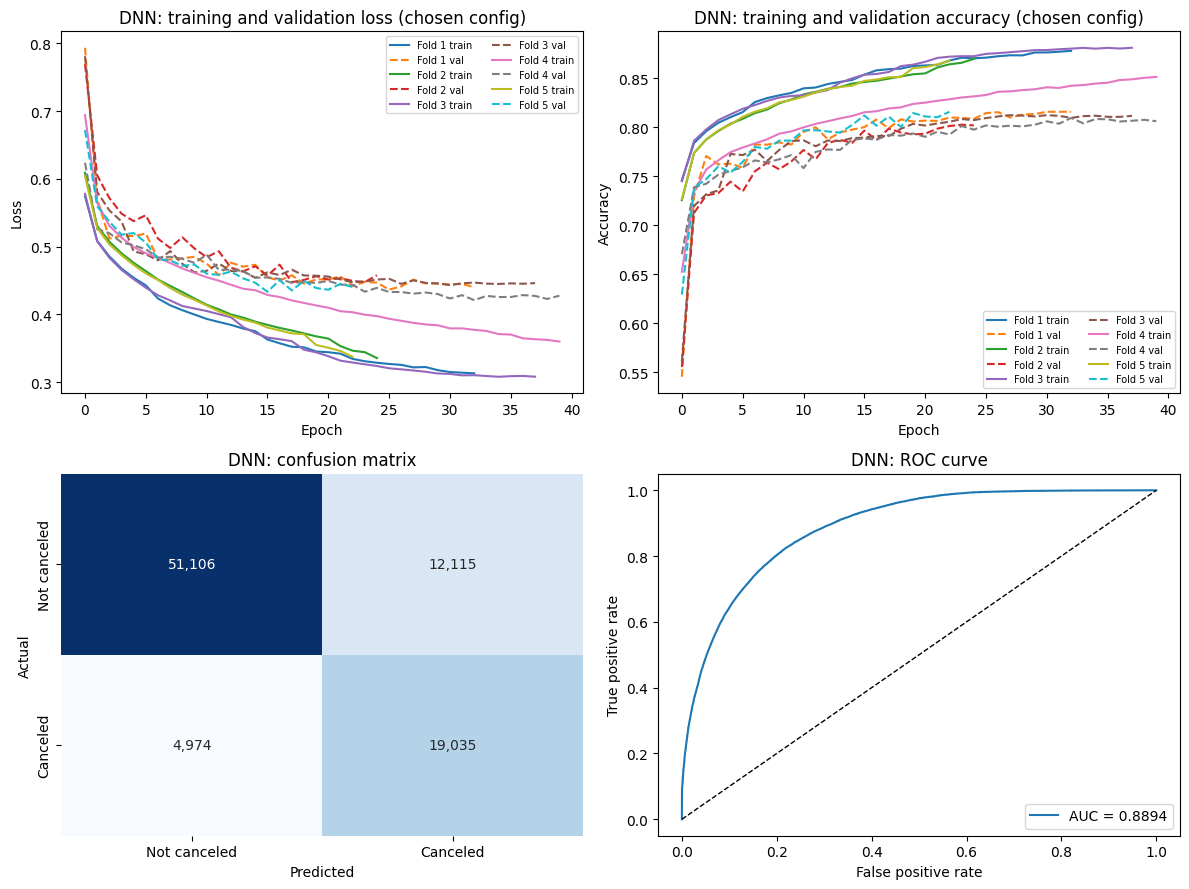

In [15]:
# Cell 13: Evaluate DNN
m = 'DNN'
tag = 'dnn'
res = pd.DataFrame([r for r in results_rows if r['Model'] == m]).drop(columns='Model')
print(f'===== {m}: results per split =====')
print(res.round(4).to_string(index=False))
print('\nMean ± std:')
for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    print(f'  {col:<10} {res[col].mean():.4f} ± {res[col].std():.4f}')
mask = ~np.isnan(oof_proba[m])
pred = (oof_proba[m][mask] >= 0.5).astype(int)
print(f'\n===== {m}: classification report (pooled test predictions) =====')
print(classification_report(y[mask], pred, target_names=['Not canceled', 'Canceled'], digits=4))
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for k, hist in enumerate(histories[m]):
    axes[0, 0].plot(hist['loss'], label=f'{split_names[k]} train')
    axes[0, 0].plot(hist['val_loss'], '--', label=f'{split_names[k]} val')
    axes[0, 1].plot(hist['accuracy'], label=f'{split_names[k]} train')
    axes[0, 1].plot(hist['val_accuracy'], '--', label=f'{split_names[k]} val')
axes[0, 0].set_title(f'{m}: training and validation loss (chosen config)')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend(fontsize=7, ncol=2)
axes[0, 1].set_title(f'{m}: training and validation accuracy (chosen config)')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend(fontsize=7, ncol=2)
ax_cm, ax_roc = axes[1, 0], axes[1, 1]
cm = confusion_matrix(y[mask], pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax_cm,
            xticklabels=['Not canceled', 'Canceled'], yticklabels=['Not canceled', 'Canceled'])
ax_cm.set_title(f'{m}: confusion matrix')
ax_cm.set_xlabel('Predicted')
ax_cm.set_ylabel('Actual')
fpr, tpr, _ = roc_curve(y[mask], oof_proba[m][mask])
ax_roc.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y[mask], oof_proba[m][mask]):.4f}')
ax_roc.plot([0, 1], [0, 1], 'k--', lw=1)
ax_roc.set_title(f'{m}: ROC curve')
ax_roc.set_xlabel('False positive rate')
ax_roc.set_ylabel('True positive rate')
ax_roc.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/eval_{tag}.png', dpi=300)
plt.show()


## 5. CNN+DNN Hybrid

In [16]:
# Cell 14: Train CNN+DNN Hybrid (hyperparameter search inside each fold)
m = 'CNN+DNN Hybrid'
results_rows = [r for r in results_rows if r['Model'] != m]
histories[m] = []
for s in range(N_SPLITS):
    best_auc, best_p, best_cfg, best_time, search_time, best_hist = -1.0, None, None, 0.0, 0.0, None
    for ci, c in enumerate(dl_configs):
        tf.keras.backend.clear_session()
        tf.random.set_seed(SEED + s)
        w, dr = c['width'], c['dropout']
        inp = Input(shape=(n_feat,))
        cb = Reshape((n_feat, 1))(inp)
        cb = Conv1D(int(64 * w), kernel_size=3, activation='relu', padding='same', kernel_regularizer=l2(1e-4))(cb)
        cb = BatchNormalization()(cb)
        cb = Conv1D(int(128 * w), kernel_size=3, activation='relu', padding='same', kernel_regularizer=l2(1e-4))(cb)
        cb = BatchNormalization()(cb)
        cb = Flatten()(cb)
        cb = Dense(int(128 * w), activation='relu', kernel_regularizer=l2(1e-4))(cb)
        db = Dense(int(256 * w), activation='relu', kernel_regularizer=l2(1e-4))(inp)
        db = BatchNormalization()(db)
        db = Dropout(dr)(db)
        db = Dense(int(128 * w), activation='relu', kernel_regularizer=l2(1e-4))(db)
        hb = Concatenate()([cb, db])
        hb = BatchNormalization()(hb)
        hb = Dropout(dr)(hb)
        hb = Dense(int(64 * w), activation='relu', kernel_regularizer=l2(1e-4))(hb)
        hb = Dropout(dr)(hb)
        out = Dense(1, activation='sigmoid')(hb)
        net = Model(inp, out)
        net.compile(optimizer=Adam(learning_rate=c['learning_rate']), loss='binary_crossentropy', metrics=['accuracy'])
        t0 = time.time()
        h = net.fit(split_train_X[s], split_train_y[s], validation_data=(split_val_X[s], split_val_y[s]),
                    epochs=EPOCHS, batch_size=c['batch_size'], verbose=0,
                    callbacks=[EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True),
                               ReduceLROnPlateau(monitor='val_loss', patience=3, factor=0.5)])
        fit_time = time.time() - t0
        search_time += fit_time
        val_auc = roc_auc_score(split_val_y[s], net.predict(split_val_X[s], batch_size=2048, verbose=0).ravel())
        if val_auc > best_auc:
            best_auc, best_cfg, best_time, best_hist = val_auc, ci, fit_time, h.history
            best_p = net.predict(split_test_X[s], batch_size=2048, verbose=0).ravel()
            if s == 0:
                net.save(f'{OUT_DIR}/hybrid_fold1_best.keras')
    histories[m].append(best_hist)
    pred = (best_p >= 0.5).astype(int)
    yt = split_test_y[s]
    oof_proba[m][split_test_idx[s]] = best_p
    results_rows.append({'Split': split_names[s], 'Model': m, 'Accuracy': accuracy_score(yt, pred),
                         'Precision': precision_score(yt, pred), 'Recall': recall_score(yt, pred),
                         'F1': f1_score(yt, pred), 'ROC-AUC': roc_auc_score(yt, best_p),
                         'PR-AUC': average_precision_score(yt, best_p), 'Fit time of chosen config (s)': best_time,
                         'Search time (s)': search_time, 'Chosen config': best_cfg, 'Validation ROC-AUC': best_auc})
    print(f'{split_names[s]}: config={best_cfg}  val AUC={best_auc:.4f}  test Acc={results_rows[-1]["Accuracy"]:.4f}  '
          f'F1={results_rows[-1]["F1"]:.4f}  AUC={results_rows[-1]["ROC-AUC"]:.4f}  search={search_time:.0f}s')


Fold 1: config=4  val AUC=0.9023  test Acc=0.8389  F1=0.7061  AUC=0.9022  search=373s
Fold 2: config=2  val AUC=0.8991  test Acc=0.8318  F1=0.6930  AUC=0.8984  search=481s
Fold 3: config=4  val AUC=0.9020  test Acc=0.8284  F1=0.6914  AUC=0.8944  search=513s
Fold 4: config=4  val AUC=0.9020  test Acc=0.8369  F1=0.6787  AUC=0.8991  search=424s
Fold 5: config=4  val AUC=0.9019  test Acc=0.8287  F1=0.6906  AUC=0.8944  search=388s


===== CNN+DNN Hybrid: results per split =====
 Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Fit time of chosen config (s)  Search time (s)  Chosen config  Validation ROC-AUC
Fold 1    0.8389     0.7089  0.7034 0.7061   0.9022  0.7879                       143.0513         372.5131              4              0.9023
Fold 2    0.8318     0.6962  0.6897 0.6930   0.8984  0.7744                       128.2019         480.9799              2              0.8991
Fold 3    0.8284     0.6847  0.6983 0.6914   0.8944  0.7707                       141.7392         513.0635              4              0.9020
Fold 4    0.8369     0.7411  0.6260 0.6787   0.8991  0.7791                        90.5372         423.7031              4              0.9020
Fold 5    0.8287     0.6869  0.6943 0.6906   0.8944  0.7665                       113.0373         387.8529              4              0.9019

Mean ± std:
  Accuracy   0.8329 ± 0.0047
  Precision  0.7036 ± 0.0231
  Recall     0.6823 ± 0.0

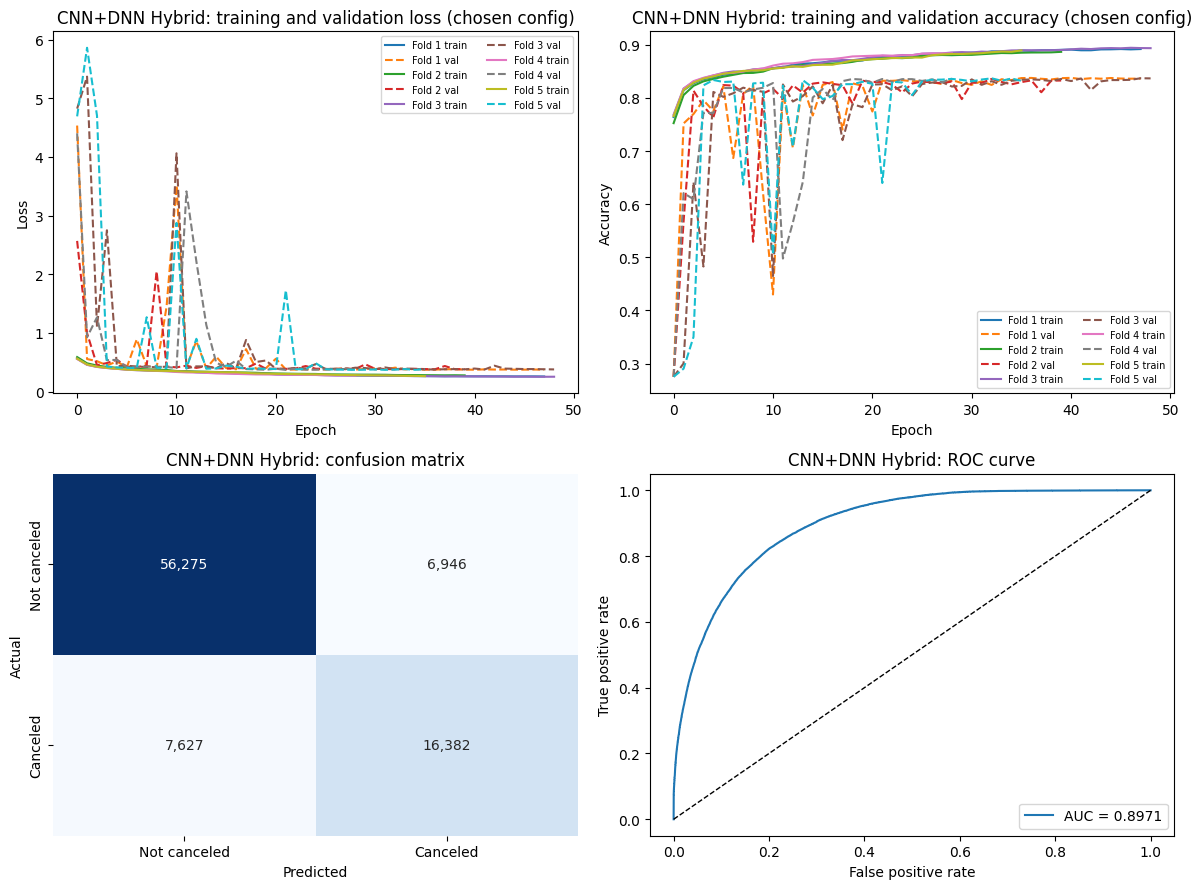

In [17]:
# Cell 15: Evaluate CNN+DNN Hybrid
m = 'CNN+DNN Hybrid'
tag = 'hybrid'
res = pd.DataFrame([r for r in results_rows if r['Model'] == m]).drop(columns='Model')
print(f'===== {m}: results per split =====')
print(res.round(4).to_string(index=False))
print('\nMean ± std:')
for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    print(f'  {col:<10} {res[col].mean():.4f} ± {res[col].std():.4f}')
mask = ~np.isnan(oof_proba[m])
pred = (oof_proba[m][mask] >= 0.5).astype(int)
print(f'\n===== {m}: classification report (pooled test predictions) =====')
print(classification_report(y[mask], pred, target_names=['Not canceled', 'Canceled'], digits=4))
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for k, hist in enumerate(histories[m]):
    axes[0, 0].plot(hist['loss'], label=f'{split_names[k]} train')
    axes[0, 0].plot(hist['val_loss'], '--', label=f'{split_names[k]} val')
    axes[0, 1].plot(hist['accuracy'], label=f'{split_names[k]} train')
    axes[0, 1].plot(hist['val_accuracy'], '--', label=f'{split_names[k]} val')
axes[0, 0].set_title(f'{m}: training and validation loss (chosen config)')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend(fontsize=7, ncol=2)
axes[0, 1].set_title(f'{m}: training and validation accuracy (chosen config)')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend(fontsize=7, ncol=2)
ax_cm, ax_roc = axes[1, 0], axes[1, 1]
cm = confusion_matrix(y[mask], pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax_cm,
            xticklabels=['Not canceled', 'Canceled'], yticklabels=['Not canceled', 'Canceled'])
ax_cm.set_title(f'{m}: confusion matrix')
ax_cm.set_xlabel('Predicted')
ax_cm.set_ylabel('Actual')
fpr, tpr, _ = roc_curve(y[mask], oof_proba[m][mask])
ax_roc.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y[mask], oof_proba[m][mask]):.4f}')
ax_roc.plot([0, 1], [0, 1], 'k--', lw=1)
ax_roc.set_title(f'{m}: ROC curve')
ax_roc.set_xlabel('False positive rate')
ax_roc.set_ylabel('True positive rate')
ax_roc.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/eval_{tag}.png', dpi=300)
plt.show()


## 6. XGBoost

In [18]:
# Cell 16: Train XGBoost (hyperparameter search inside each fold)
m = 'XGBoost'
results_rows = [r for r in results_rows if r['Model'] != m]
histories[m] = []
for s in range(N_SPLITS):
    best_auc, best_p, best_cfg, best_time, search_time, best_hist = -1.0, None, None, 0.0, 0.0, None
    for ci, c in enumerate(xgb_configs):
        xgb_model = xgb.XGBClassifier(n_estimators=2000, eval_metric='logloss', early_stopping_rounds=50,
                                      tree_method='hist', device=XGB_DEVICE, random_state=SEED, n_jobs=-1, **c)
        t0 = time.time()
        xgb_model.fit(split_train_X[s], split_train_y[s],
                      eval_set=[(split_train_X[s], split_train_y[s]), (split_val_X[s], split_val_y[s])], verbose=False)
        fit_time = time.time() - t0
        search_time += fit_time
        val_auc = roc_auc_score(split_val_y[s], xgb_model.predict_proba(split_val_X[s])[:, 1])
        if val_auc > best_auc:
            ev = xgb_model.evals_result()
            best_auc, best_cfg, best_time = val_auc, ci, fit_time
            best_hist = {'loss': ev['validation_0']['logloss'], 'val_loss': ev['validation_1']['logloss']}
            best_p = xgb_model.predict_proba(split_test_X[s])[:, 1]
    histories[m].append(best_hist)
    pred = (best_p >= 0.5).astype(int)
    yt = split_test_y[s]
    oof_proba[m][split_test_idx[s]] = best_p
    results_rows.append({'Split': split_names[s], 'Model': m, 'Accuracy': accuracy_score(yt, pred),
                         'Precision': precision_score(yt, pred), 'Recall': recall_score(yt, pred),
                         'F1': f1_score(yt, pred), 'ROC-AUC': roc_auc_score(yt, best_p),
                         'PR-AUC': average_precision_score(yt, best_p), 'Fit time of chosen config (s)': best_time,
                         'Search time (s)': search_time, 'Chosen config': best_cfg, 'Validation ROC-AUC': best_auc})
    print(f'{split_names[s]}: config={best_cfg}  val AUC={best_auc:.4f}  test Acc={results_rows[-1]["Accuracy"]:.4f}  '
          f'F1={results_rows[-1]["F1"]:.4f}  AUC={results_rows[-1]["ROC-AUC"]:.4f}  search={search_time:.0f}s')


Fold 1: config=2  val AUC=0.9084  test Acc=0.8442  F1=0.7042  AUC=0.9063  search=90s
Fold 2: config=4  val AUC=0.9089  test Acc=0.8420  F1=0.6983  AUC=0.9049  search=85s
Fold 3: config=11  val AUC=0.9073  test Acc=0.8370  F1=0.6909  AUC=0.8987  search=86s
Fold 4: config=4  val AUC=0.9099  test Acc=0.8414  F1=0.6978  AUC=0.9064  search=87s
Fold 5: config=3  val AUC=0.9107  test Acc=0.8405  F1=0.6973  AUC=0.9043  search=88s


===== XGBoost: results per split =====
 Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Fit time of chosen config (s)  Search time (s)  Chosen config  Validation ROC-AUC
Fold 1    0.8442     0.7374  0.6738 0.7042   0.9063  0.7953                         9.9699          90.2601              2              0.9084
Fold 2    0.8420     0.7358  0.6645 0.6983   0.9049  0.7906                         5.9563          85.2408              4              0.9089
Fold 3    0.8370     0.7225  0.6620 0.6909   0.8987  0.7805                         5.5968          85.7206             11              0.9073
Fold 4    0.8414     0.7337  0.6651 0.6978   0.9064  0.7928                         5.0630          86.5842              4              0.9099
Fold 5    0.8405     0.7302  0.6672 0.6973   0.9043  0.7880                         5.2069          88.4262              3              0.9107

Mean ± std:
  Accuracy   0.8410 ± 0.0026
  Precision  0.7319 ± 0.0059
  Recall     0.6665 ± 0.0045
  F

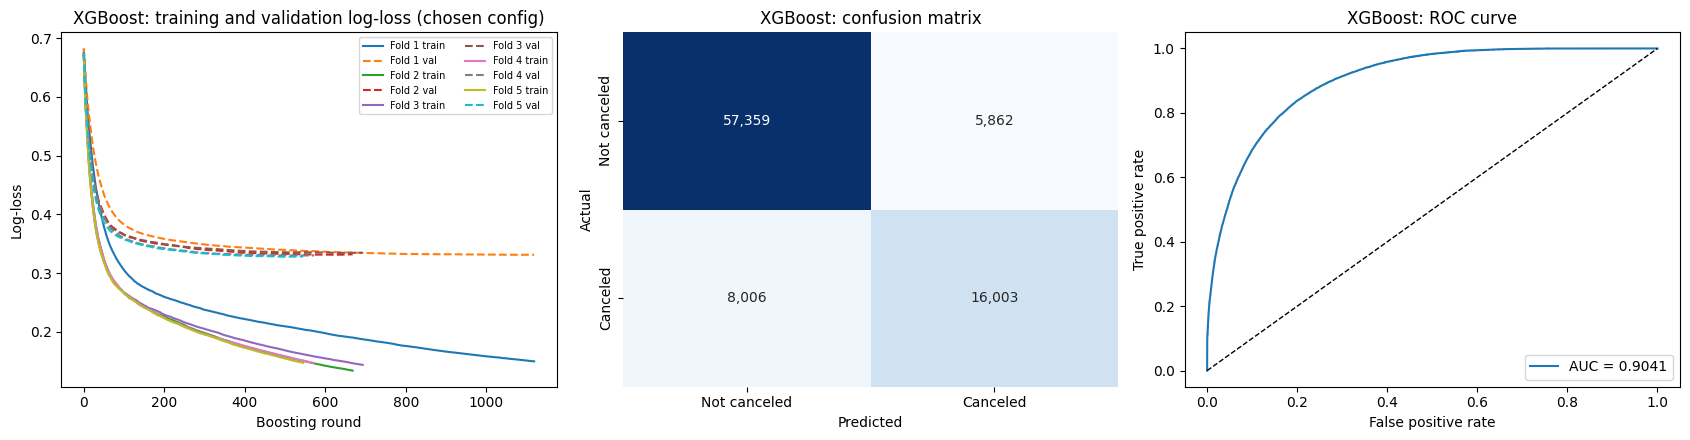

In [19]:
# Cell 17: Evaluate XGBoost
m = 'XGBoost'
tag = 'xgboost'
res = pd.DataFrame([r for r in results_rows if r['Model'] == m]).drop(columns='Model')
print(f'===== {m}: results per split =====')
print(res.round(4).to_string(index=False))
print('\nMean ± std:')
for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    print(f'  {col:<10} {res[col].mean():.4f} ± {res[col].std():.4f}')
mask = ~np.isnan(oof_proba[m])
pred = (oof_proba[m][mask] >= 0.5).astype(int)
print(f'\n===== {m}: classification report (pooled test predictions) =====')
print(classification_report(y[mask], pred, target_names=['Not canceled', 'Canceled'], digits=4))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for k, hist in enumerate(histories[m]):
    axes[0].plot(hist['loss'], label=f'{split_names[k]} train')
    axes[0].plot(hist['val_loss'], '--', label=f'{split_names[k]} val')
axes[0].set_title(f'{m}: training and validation log-loss (chosen config)')
axes[0].set_xlabel('Boosting round')
axes[0].set_ylabel('Log-loss')
axes[0].legend(fontsize=7, ncol=2)
ax_cm, ax_roc = axes[1], axes[2]
cm = confusion_matrix(y[mask], pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax_cm,
            xticklabels=['Not canceled', 'Canceled'], yticklabels=['Not canceled', 'Canceled'])
ax_cm.set_title(f'{m}: confusion matrix')
ax_cm.set_xlabel('Predicted')
ax_cm.set_ylabel('Actual')
fpr, tpr, _ = roc_curve(y[mask], oof_proba[m][mask])
ax_roc.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y[mask], oof_proba[m][mask]):.4f}')
ax_roc.plot([0, 1], [0, 1], 'k--', lw=1)
ax_roc.set_title(f'{m}: ROC curve')
ax_roc.set_xlabel('False positive rate')
ax_roc.set_ylabel('True positive rate')
ax_roc.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/eval_{tag}.png', dpi=300)
plt.show()


## 7. LightGBM

In [20]:
# Cell 18: Train LightGBM (hyperparameter search inside each fold)
m = 'LightGBM'
results_rows = [r for r in results_rows if r['Model'] != m]
histories[m] = []
lgb_best_models = []
for s in range(N_SPLITS):
    best_auc, best_p, best_cfg, best_time, search_time, best_hist, best_model = -1.0, None, None, 0.0, 0.0, None, None
    for ci, c in enumerate(lgb_configs):
        lgb_model = lgb.LGBMClassifier(n_estimators=2000, subsample_freq=1, random_state=SEED, n_jobs=-1, verbose=-1, **c)
        t0 = time.time()
        lgb_model.fit(split_train_X[s], split_train_y[s],
                      eval_set=[(split_train_X[s], split_train_y[s]), (split_val_X[s], split_val_y[s])],
                      eval_metric='binary_logloss', callbacks=[lgb.early_stopping(50, verbose=False)])
        fit_time = time.time() - t0
        search_time += fit_time
        val_auc = roc_auc_score(split_val_y[s], lgb_model.predict_proba(split_val_X[s])[:, 1])
        if val_auc > best_auc:
            ev = lgb_model.evals_result_
            best_auc, best_cfg, best_time, best_model = val_auc, ci, fit_time, lgb_model
            best_hist = {'loss': ev['training']['binary_logloss'], 'val_loss': ev['valid_1']['binary_logloss']}
            best_p = lgb_model.predict_proba(split_test_X[s])[:, 1]
    histories[m].append(best_hist)
    lgb_best_models.append(best_model)
    pred = (best_p >= 0.5).astype(int)
    yt = split_test_y[s]
    oof_proba[m][split_test_idx[s]] = best_p
    results_rows.append({'Split': split_names[s], 'Model': m, 'Accuracy': accuracy_score(yt, pred),
                         'Precision': precision_score(yt, pred), 'Recall': recall_score(yt, pred),
                         'F1': f1_score(yt, pred), 'ROC-AUC': roc_auc_score(yt, best_p),
                         'PR-AUC': average_precision_score(yt, best_p), 'Fit time of chosen config (s)': best_time,
                         'Search time (s)': search_time, 'Chosen config': best_cfg, 'Validation ROC-AUC': best_auc})
    print(f'{split_names[s]}: config={best_cfg}  val AUC={best_auc:.4f}  test Acc={results_rows[-1]["Accuracy"]:.4f}  '
          f'F1={results_rows[-1]["F1"]:.4f}  AUC={results_rows[-1]["ROC-AUC"]:.4f}  search={search_time:.0f}s')


Fold 1: config=2  val AUC=0.9120  test Acc=0.8461  F1=0.7073  AUC=0.9087  search=301s
Fold 2: config=0  val AUC=0.9102  test Acc=0.8425  F1=0.7020  AUC=0.9071  search=289s
Fold 3: config=2  val AUC=0.9103  test Acc=0.8382  F1=0.6933  AUC=0.9006  search=274s
Fold 4: config=1  val AUC=0.9120  test Acc=0.8421  F1=0.6983  AUC=0.9067  search=281s
Fold 5: config=12  val AUC=0.9129  test Acc=0.8424  F1=0.7010  AUC=0.9055  search=275s


===== LightGBM: results per split =====
 Split  Accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Fit time of chosen config (s)  Search time (s)  Chosen config  Validation ROC-AUC
Fold 1    0.8461     0.7420  0.6757 0.7073   0.9087  0.8005                        27.6764         300.9293              2              0.9120
Fold 2    0.8425     0.7326  0.6739 0.7020   0.9071  0.7935                        25.2255         288.6547              0              0.9102
Fold 3    0.8382     0.7247  0.6645 0.6933   0.9006  0.7828                        24.3837         274.1524              2              0.9103
Fold 4    0.8421     0.7364  0.6639 0.6983   0.9067  0.7949                        14.4081         281.0342              1              0.9120
Fold 5    0.8424     0.7338  0.6710 0.7010   0.9055  0.7889                        28.6221         274.8523             12              0.9129

Mean ± std:
  Accuracy   0.8423 ± 0.0028
  Precision  0.7339 ± 0.0063
  Recall     0.6698 ± 0.0054
  

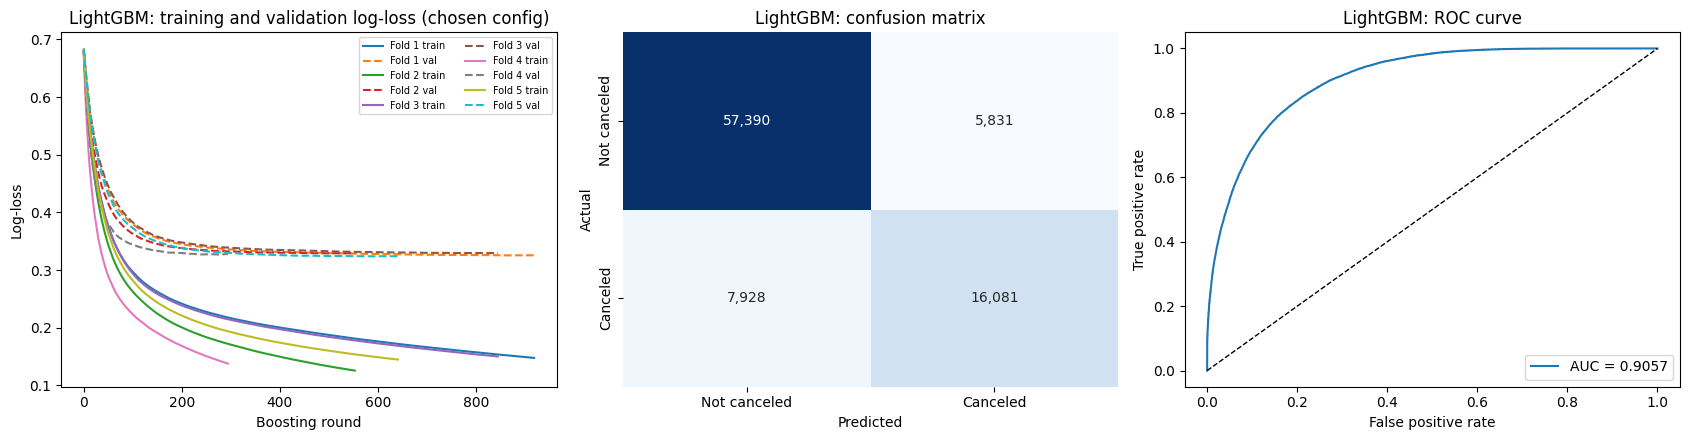

In [21]:
# Cell 19: Evaluate LightGBM
m = 'LightGBM'
tag = 'lightgbm'
res = pd.DataFrame([r for r in results_rows if r['Model'] == m]).drop(columns='Model')
print(f'===== {m}: results per split =====')
print(res.round(4).to_string(index=False))
print('\nMean ± std:')
for col in ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC']:
    print(f'  {col:<10} {res[col].mean():.4f} ± {res[col].std():.4f}')
mask = ~np.isnan(oof_proba[m])
pred = (oof_proba[m][mask] >= 0.5).astype(int)
print(f'\n===== {m}: classification report (pooled test predictions) =====')
print(classification_report(y[mask], pred, target_names=['Not canceled', 'Canceled'], digits=4))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for k, hist in enumerate(histories[m]):
    axes[0].plot(hist['loss'], label=f'{split_names[k]} train')
    axes[0].plot(hist['val_loss'], '--', label=f'{split_names[k]} val')
axes[0].set_title(f'{m}: training and validation log-loss (chosen config)')
axes[0].set_xlabel('Boosting round')
axes[0].set_ylabel('Log-loss')
axes[0].legend(fontsize=7, ncol=2)
ax_cm, ax_roc = axes[1], axes[2]
cm = confusion_matrix(y[mask], pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax_cm,
            xticklabels=['Not canceled', 'Canceled'], yticklabels=['Not canceled', 'Canceled'])
ax_cm.set_title(f'{m}: confusion matrix')
ax_cm.set_xlabel('Predicted')
ax_cm.set_ylabel('Actual')
fpr, tpr, _ = roc_curve(y[mask], oof_proba[m][mask])
ax_roc.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y[mask], oof_proba[m][mask]):.4f}')
ax_roc.plot([0, 1], [0, 1], 'k--', lw=1)
ax_roc.set_title(f'{m}: ROC curve')
ax_roc.set_xlabel('False positive rate')
ax_roc.set_ylabel('True positive rate')
ax_roc.legend(loc='lower right')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/eval_{tag}.png', dpi=300)
plt.show()


## 8. Comparison of all models

In [22]:
# Cell 20: Main results table and chosen hyperparameters
results_df = pd.DataFrame(results_rows)
results_df.to_csv(f'{OUT_DIR}/split_results.csv', index=False)
np.save(f'{OUT_DIR}/test_proba.npy', oof_proba)
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'PR-AUC', 'Fit time of chosen config (s)', 'Search time (s)']
mean_df = results_df.groupby('Model')[metrics].mean().reindex(model_names)
std_df = results_df.groupby('Model')[metrics].std().reindex(model_names)
main_table = mean_df.round(4).astype(str) + ' ± ' + std_df.round(4).astype(str)
for col in ['Fit time of chosen config (s)', 'Search time (s)']:
    main_table[col] = mean_df[col].round(1).astype(str) + ' ± ' + std_df[col].round(1).astype(str)
main_table.to_csv(f'{OUT_DIR}/table_main_results.csv')
print(main_table.to_string())

# chosen hyperparameters per split
chosen_rows = []
for r in results_rows:
    m = r['Model']
    if m == 'Logistic Regression':
        params = {'C': lr_grid[r['Chosen config']]}
    elif m == 'XGBoost':
        params = xgb_configs[r['Chosen config']]
    elif m == 'LightGBM':
        params = lgb_configs[r['Chosen config']]
    else:
        params = dl_configs[r['Chosen config']]
    chosen_rows.append({'Model': m, 'Split': r['Split'], 'Validation ROC-AUC': round(r['Validation ROC-AUC'], 4), **params})
chosen_df = pd.DataFrame(chosen_rows)
chosen_df.to_csv(f'{OUT_DIR}/table_chosen_hyperparameters.csv', index=False)
print('\n=== Chosen hyperparameters per split ===')
print(chosen_df.to_string(index=False))


                            Accuracy        Precision           Recall               F1          ROC-AUC           PR-AUC Fit time of chosen config (s) Search time (s)
Model                                                                                                                                                                  
Logistic Regression  0.7484 ± 0.0018  0.5299 ± 0.0024  0.7626 ± 0.0034  0.6253 ± 0.0018  0.8363 ± 0.0016  0.6679 ± 0.0045                     3.4 ± 1.0      12.5 ± 2.4
1D CNN               0.8157 ± 0.0057   0.6504 ± 0.024  0.7209 ± 0.0417  0.6827 ± 0.0082  0.8866 ± 0.0034  0.7515 ± 0.0083                   78.6 ± 17.3    265.6 ± 34.8
DNN                   0.8041 ± 0.005   0.6111 ± 0.008  0.7928 ± 0.0048  0.6902 ± 0.0065  0.8899 ± 0.0035  0.7634 ± 0.0081                    53.5 ± 9.4    286.2 ± 45.7
CNN+DNN Hybrid       0.8329 ± 0.0047  0.7036 ± 0.0231  0.6823 ± 0.0319   0.692 ± 0.0097  0.8977 ± 0.0033  0.7757 ± 0.0083                  123.3 ± 22.0    435.6

In [23]:
# Cell 21: Per-class results
report_rows = []
for m in model_names:
    mask = ~np.isnan(oof_proba[m])
    rep = classification_report(y[mask], (oof_proba[m][mask] >= 0.5).astype(int),
                                target_names=['Not canceled', 'Canceled'], output_dict=True)
    for cls in ['Not canceled', 'Canceled']:
        report_rows.append({'Model': m, 'Class': cls, 'Precision': round(rep[cls]['precision'], 4),
                            'Recall': round(rep[cls]['recall'], 4), 'F1': round(rep[cls]['f1-score'], 4),
                            'Support': int(rep[cls]['support'])})
report_df = pd.DataFrame(report_rows)
report_df.to_csv(f'{OUT_DIR}/table_per_class.csv', index=False)
print(report_df.to_string(index=False))


              Model        Class  Precision  Recall     F1  Support
Logistic Regression Not canceled     0.8918  0.7430 0.8107    63221
Logistic Regression     Canceled     0.5299  0.7626 0.6253    24009
             1D CNN Not canceled     0.8893  0.8517 0.8701    63221
             1D CNN     Canceled     0.6487  0.7209 0.6829    24009
                DNN Not canceled     0.9113  0.8084 0.8568    63221
                DNN     Canceled     0.6111  0.7928 0.6902    24009
     CNN+DNN Hybrid Not canceled     0.8806  0.8901 0.8854    63221
     CNN+DNN Hybrid     Canceled     0.7022  0.6823 0.6921    24009
            XGBoost Not canceled     0.8775  0.9073 0.8922    63221
            XGBoost     Canceled     0.7319  0.6665 0.6977    24009
           LightGBM Not canceled     0.8786  0.9078 0.8930    63221
           LightGBM     Canceled     0.7339  0.6698 0.7004    24009


In [24]:
# Cell 22: Statistical tests
f1_matrix = results_df.pivot(index='Split', columns='Model', values='F1')[model_names]
stat, p_friedman = friedmanchisquare(*[f1_matrix[m] for m in model_names])
print(f'Friedman test on F1 across splits: chi2 = {stat:.3f}, p = {p_friedman:.4g}')
dl_models = ['1D CNN', 'DNN', 'CNN+DNN Hybrid']
gb_models = ['XGBoost', 'LightGBM']
best_dl = mean_df.loc[dl_models, 'F1'].idxmax()
best_gb = mean_df.loc[gb_models, 'F1'].idxmax()
mask = ~np.isnan(oof_proba[best_dl])
correct_dl = (oof_proba[best_dl][mask] >= 0.5).astype(int) == y[mask]
correct_gb = (oof_proba[best_gb][mask] >= 0.5).astype(int) == y[mask]
mc_table = [[np.sum(correct_dl & correct_gb), np.sum(correct_dl & ~correct_gb)],
            [np.sum(~correct_dl & correct_gb), np.sum(~correct_dl & ~correct_gb)]]
mc = mcnemar(mc_table, exact=False, correction=True)
print(f'McNemar {best_dl} vs {best_gb}: chi2 = {mc.statistic:.3f}, p = {mc.pvalue:.3g}')
print('[[both correct, only DL correct], [only GB correct, both wrong]] =', np.array(mc_table).tolist())
pd.DataFrame({'Test': ['Friedman (F1, all models)', f'McNemar ({best_dl} vs {best_gb})'],
              'Statistic': [round(stat, 3), round(mc.statistic, 3)], 'p-value': [p_friedman, mc.pvalue],
              'Detail': ['', f'only {best_gb} correct: {mc_table[1][0]}; only {best_dl} correct: {mc_table[0][1]}']}
             ).to_csv(f'{OUT_DIR}/table_statistical_tests.csv', index=False)


Friedman test on F1 across splits: chi2 = 22.029, p = 0.0005171
McNemar CNN+DNN Hybrid vs LightGBM: chi2 = 103.698, p = 2.36e-24
[[both correct, only DL correct], [only GB correct, both wrong]] = [[69877, 2780], [3594, 10979]]


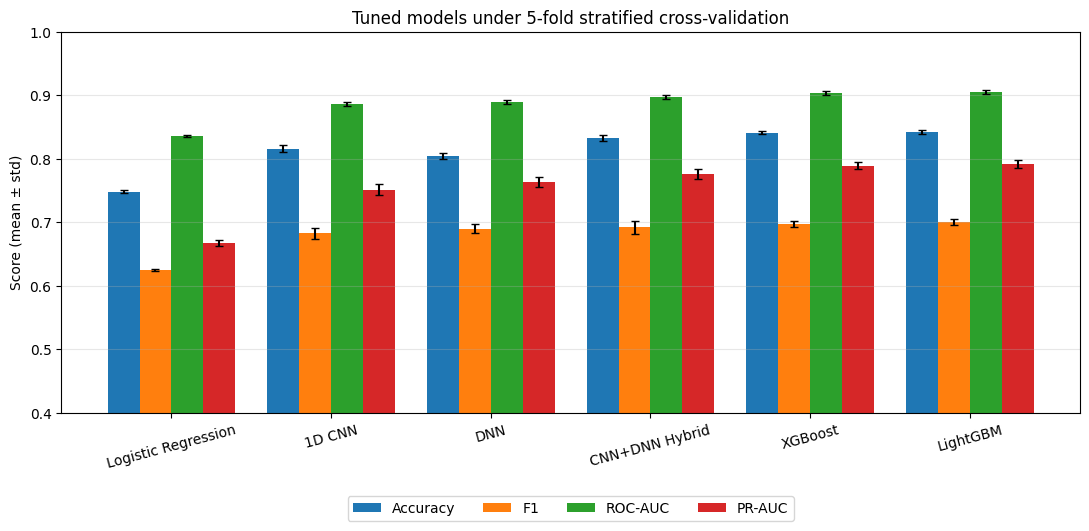

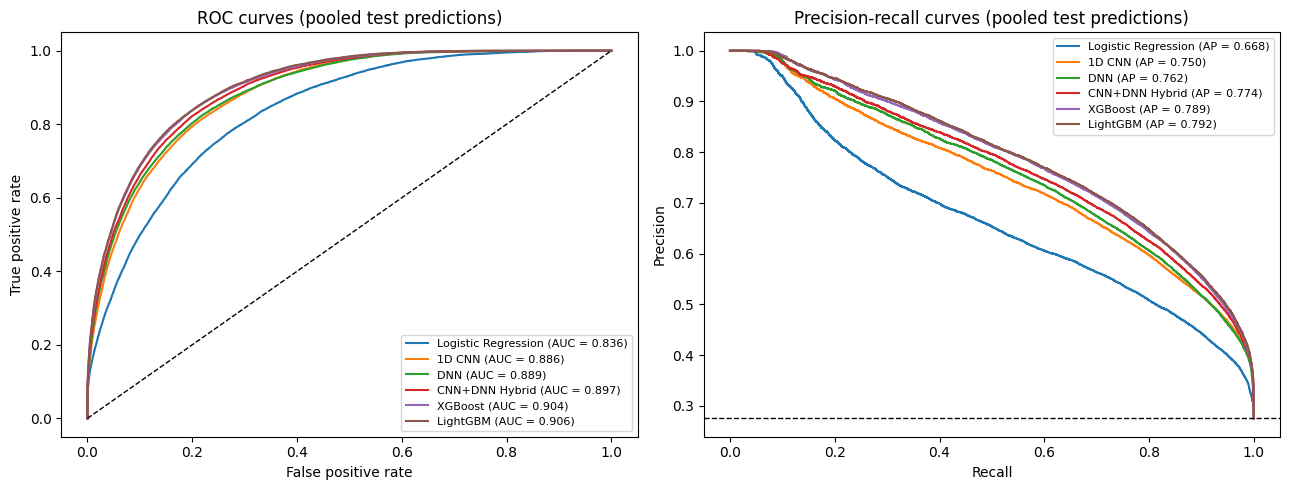

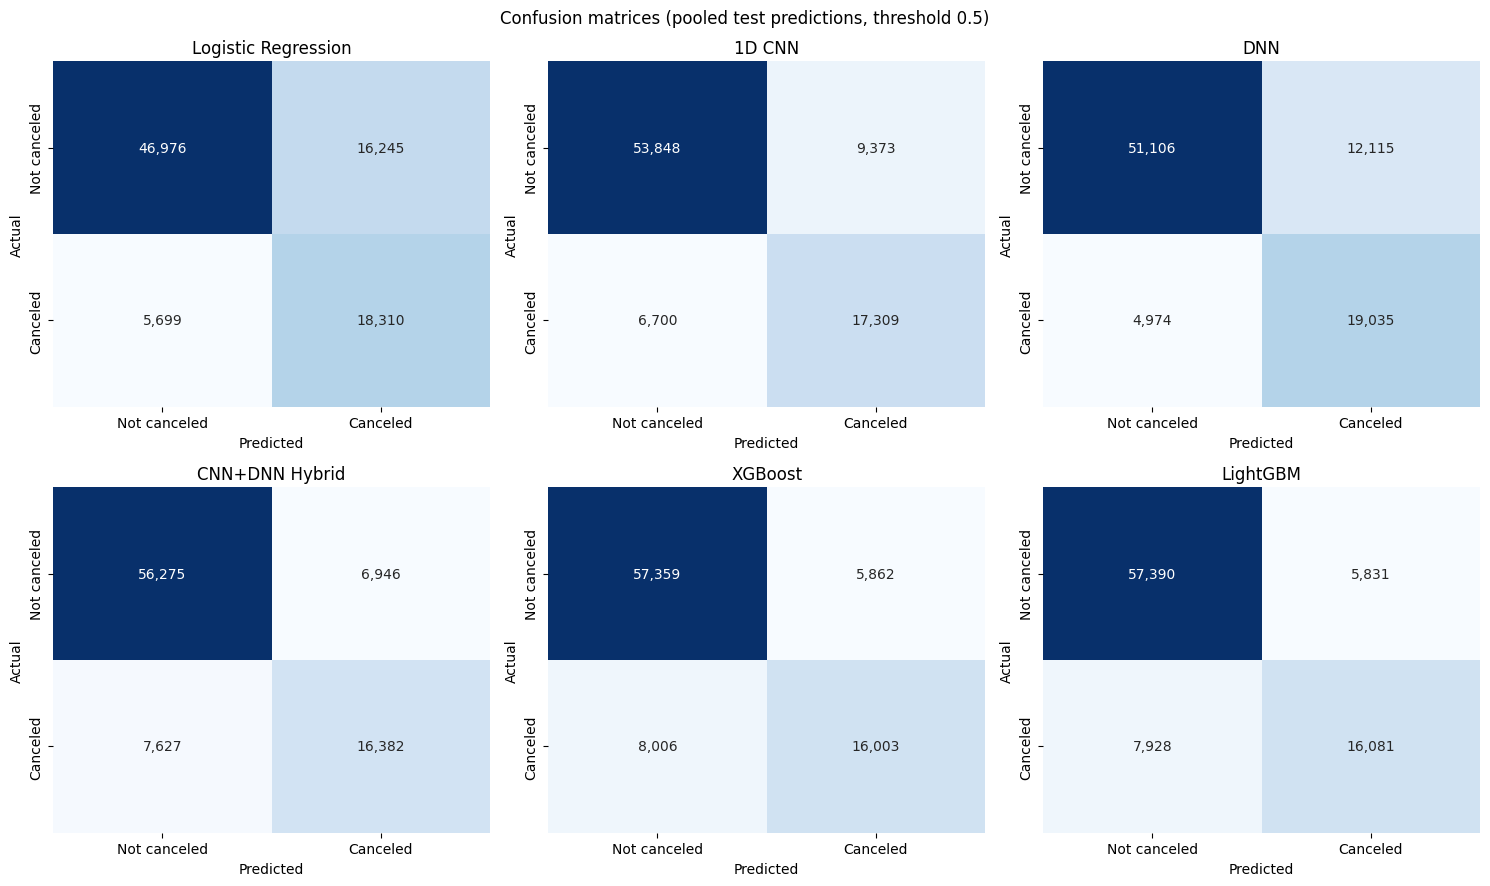

In [25]:
# Cell 23: Figures - comparison, ROC/PR curves, confusion matrices
plot_metrics = ['Accuracy', 'F1', 'ROC-AUC', 'PR-AUC']
fig, ax = plt.subplots(figsize=(11, 5.5))
x_pos = np.arange(len(model_names))
width = 0.2
for i, met in enumerate(plot_metrics):
    ax.bar(x_pos + (i - 1.5) * width, mean_df[met], width, yerr=std_df[met], capsize=3, label=met)
ax.set_xticks(x_pos)
ax.set_xticklabels(model_names, rotation=15)
ax.set_ylim(0.4, 1.0)
ax.set_ylabel('Score (mean ± std)')
ax.set_title('Tuned models under 5-fold stratified cross-validation')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=4)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fig_model_comparison.png', dpi=300)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for m in model_names:
    mask = ~np.isnan(oof_proba[m])
    fpr, tpr, _ = roc_curve(y[mask], oof_proba[m][mask])
    axes[0].plot(fpr, tpr, label=f'{m} (AUC = {roc_auc_score(y[mask], oof_proba[m][mask]):.3f})')
    prec, rec, _ = precision_recall_curve(y[mask], oof_proba[m][mask])
    axes[1].plot(rec, prec, label=f'{m} (AP = {average_precision_score(y[mask], oof_proba[m][mask]):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_xlabel('False positive rate')
axes[0].set_ylabel('True positive rate')
axes[0].set_title('ROC curves (pooled test predictions)')
axes[0].legend(fontsize=8)
axes[1].axhline(y[~np.isnan(oof_proba[model_names[0]])].mean(), color='k', ls='--', lw=1)
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-recall curves (pooled test predictions)')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fig_roc_pr_curves.png', dpi=300)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, m in zip(axes.ravel(), model_names):
    mask = ~np.isnan(oof_proba[m])
    cm = confusion_matrix(y[mask], (oof_proba[m][mask] >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Not canceled', 'Canceled'], yticklabels=['Not canceled', 'Canceled'])
    ax.set_title(m)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.suptitle('Confusion matrices (pooled test predictions, threshold 0.5)')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fig_confusion_matrices_all.png', dpi=300)
plt.show()


## 9. Duplicate-leakage experiment

In [26]:
# Cell 24: LightGBM with and without duplicates
# Same LightGBM configuration (the one chosen most often across folds) on the ORIGINAL data
# with duplicates kept and a random 80/20 split
lgb_cfg_counts = results_df[results_df['Model'] == 'LightGBM']['Chosen config'].value_counts()
lgb_cfg = lgb_configs[int(lgb_cfg_counts.index[0])]
d = df_raw.drop(columns=leak_cols).copy()
d['children'] = d['children'].fillna(0)
d['country'] = d['country'].fillna('Unknown')
d.loc[~d['country'].isin(df['country'].unique()), 'country'] = 'Other'
d['total_guests'] = d['adults'] + d['children'] + d['babies']
d['total_nights'] = d['stays_in_weekend_nights'] + d['stays_in_week_nights']
d['was_waitlisted'] = (d['days_in_waiting_list'] > 0).astype(int)
d['is_family'] = ((d['children'] + d['babies']) > 0).astype(int)
d = d[d['total_guests'] > 0].reset_index(drop=True)
y_dup = d['is_canceled'].values
X_dup = pd.get_dummies(d.drop(columns=['is_canceled']), columns=cat_cols, dtype=float)
X_dup = X_dup.reindex(columns=feature_names, fill_value=0).astype('float32')
Xa, Xb, ya, yb = train_test_split(X_dup, y_dup, test_size=0.2, stratify=y_dup, random_state=SEED)
Xa_in, Xa_val, ya_in, ya_val = train_test_split(Xa, ya, test_size=0.1, stratify=ya, random_state=SEED)
train_rows = set(map(tuple, Xa.values))
overlap = np.mean([tuple(r) in train_rows for r in Xb.values])
print(f'Test rows that also appear exactly in the training set: {overlap:.1%}')
lgb_dup = lgb.LGBMClassifier(n_estimators=2000, subsample_freq=1, random_state=SEED, n_jobs=-1, verbose=-1, **lgb_cfg)
lgb_dup.fit(Xa_in, ya_in, eval_set=[(Xa_val, ya_val)], eval_metric='binary_logloss',
            callbacks=[lgb.early_stopping(50, verbose=False)])
p_dup = lgb_dup.predict_proba(Xb)[:, 1]
leak_table = pd.DataFrame({
    'Setting': ['With duplicates, random 80/20 split', 'Duplicates removed, 5-fold CV (this study)'],
    'Accuracy': [accuracy_score(yb, p_dup >= 0.5), mean_df.loc['LightGBM', 'Accuracy']],
    'F1': [f1_score(yb, p_dup >= 0.5), mean_df.loc['LightGBM', 'F1']],
    'ROC-AUC': [roc_auc_score(yb, p_dup), mean_df.loc['LightGBM', 'ROC-AUC']]}).round(4)
leak_table.to_csv(f'{OUT_DIR}/table_duplicate_leakage.csv', index=False)
print(leak_table.to_string(index=False))


Test rows that also appear exactly in the training set: 34.2%
                                   Setting  Accuracy     F1  ROC-AUC
       With duplicates, random 80/20 split    0.8842 0.8388   0.9543
Duplicates removed, 5-fold CV (this study)    0.8423 0.7004   0.9057


## 10. Explainability (SHAP)

Top 15 features by mean |SHAP| (LightGBM, log-odds):
required_car_parking_spaces      1.0430
country_PRT                      0.8882
total_of_special_requests        0.6348
lead_time                        0.6119
market_segment_Online TA         0.5086
adr                              0.3212
market_segment_Offline TA/TO     0.3172
arrival_date_year                0.2771
total_nights                     0.2650
stays_in_week_nights             0.2081
previous_cancellations           0.1916
customer_type_Transient          0.1875
stays_in_weekend_nights          0.1712
arrival_date_week_number         0.1343
customer_type_Transient-Party    0.1154


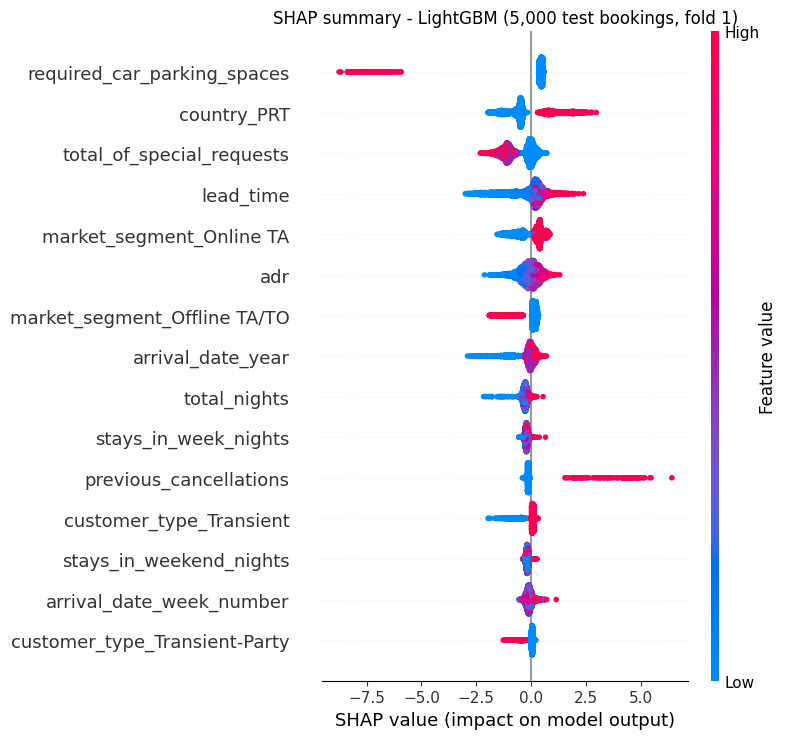

In [27]:
# Cell 25: SHAP for LightGBM - global importance and direction
# SHAP for LightGBM: the fold-1 model chosen by the search, explaining 5,000 fold-1 test bookings
shap_lgb_model = lgb_best_models[0]
rs = np.random.RandomState(SEED)
shap_rows = rs.choice(len(split_test_y[0]), size=min(5000, len(split_test_y[0])), replace=False)
X_shap = pd.DataFrame(split_test_X[0][shap_rows], columns=feature_names)
X_shap_raw = X.iloc[split_test_idx[0][shap_rows]].reset_index(drop=True)   # unscaled values for the plots
tree_explainer = shap.TreeExplainer(shap_lgb_model)
shap_lgb = tree_explainer.shap_values(X_shap)
if isinstance(shap_lgb, list):
    shap_lgb = shap_lgb[1]
shap_lgb = np.asarray(shap_lgb)
if shap_lgb.ndim == 3:
    shap_lgb = shap_lgb[:, :, 1]
mean_abs_lgb = pd.Series(np.abs(shap_lgb).mean(axis=0), index=feature_names).sort_values(ascending=False)
mean_abs_lgb.to_csv(f'{OUT_DIR}/shap_lightgbm_mean_abs.csv')
print('Top 15 features by mean |SHAP| (LightGBM, log-odds):')
print(mean_abs_lgb.head(15).round(4).to_string())

plt.figure()
shap.summary_plot(shap_lgb, features=X_shap_raw, feature_names=feature_names, max_display=15, show=False)
plt.title('SHAP summary - LightGBM (5,000 test bookings, fold 1)')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fig_shap_beeswarm_lightgbm.png', dpi=300, bbox_inches='tight')
plt.show()


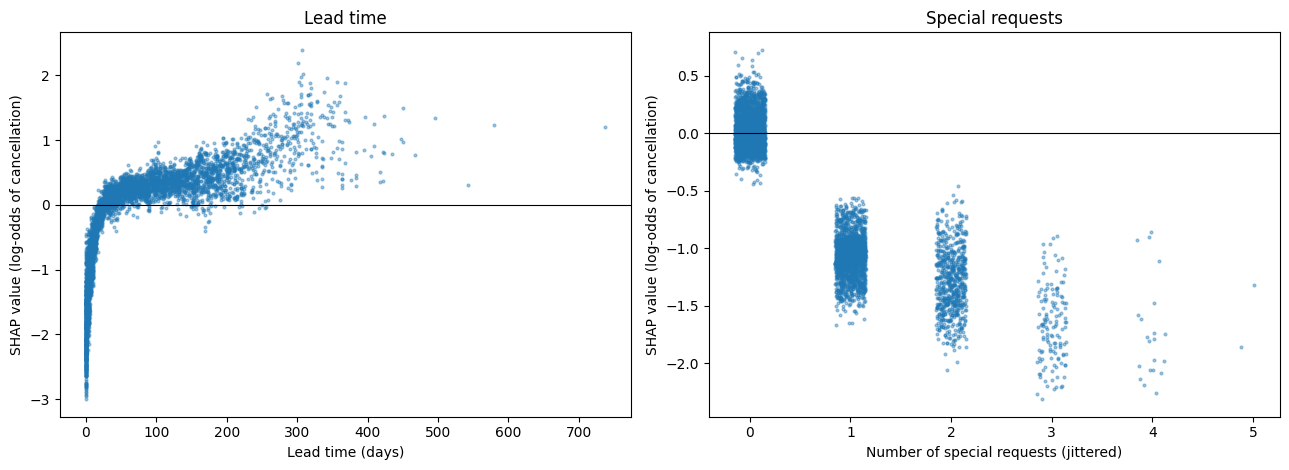

Lead time where its SHAP contribution is near zero: median 35 days


In [28]:
# Cell 26: SHAP dependence plots
# Direction of influence: SHAP dependence for the two strongest predictors (unscaled values)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
j = feature_names.index('lead_time')
axes[0].scatter(X_shap_raw['lead_time'], shap_lgb[:, j], s=4, alpha=0.4)
axes[0].axhline(0, color='k', lw=0.8)
axes[0].set_xlabel('Lead time (days)')
axes[0].set_ylabel('SHAP value (log-odds of cancellation)')
axes[0].set_title('Lead time')
j = feature_names.index('total_of_special_requests')
axes[1].scatter(X_shap_raw['total_of_special_requests'] + rs.uniform(-0.15, 0.15, len(X_shap_raw)), shap_lgb[:, j], s=4, alpha=0.4)
axes[1].axhline(0, color='k', lw=0.8)
axes[1].set_xlabel('Number of special requests (jittered)')
axes[1].set_ylabel('SHAP value (log-odds of cancellation)')
axes[1].set_title('Special requests')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fig_shap_dependence.png', dpi=300)
plt.show()

# Lead time at which the SHAP effect crosses zero (median of points within +/- 0.05 of zero)
lt_shap = shap_lgb[:, feature_names.index('lead_time')]
near_zero = np.abs(lt_shap) < 0.05
print(f'Lead time where its SHAP contribution is near zero: median {X_shap_raw.loc[near_zero, "lead_time"].median():.0f} days')


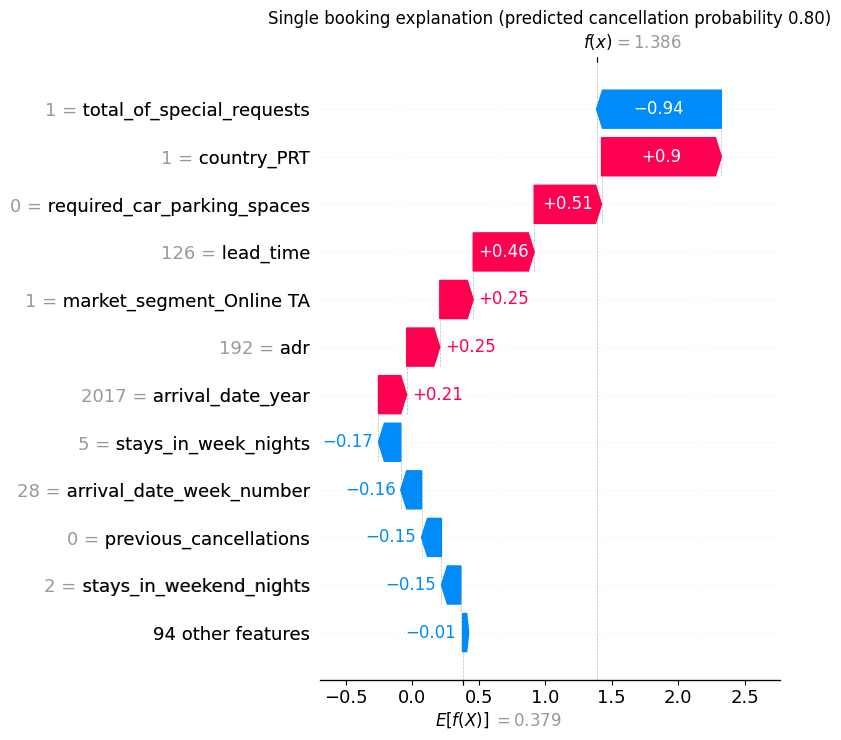

Actual outcome of this booking: Canceled


In [29]:
# Cell 27: SHAP explanation of one booking
# One individual explanation: a typical high-risk booking (predicted probability closest to 0.80)
p_shap = shap_lgb_model.predict_proba(X_shap)[:, 1]
i_hi = int(np.argmin(np.abs(p_shap - 0.80)))
base = tree_explainer.expected_value
base = float(base[1]) if np.ndim(base) else float(base)
expl = shap.Explanation(values=shap_lgb[i_hi], base_values=base, data=X_shap_raw.iloc[i_hi].values,
                        feature_names=feature_names)
plt.figure()
shap.plots.waterfall(expl, max_display=12, show=False)
plt.title(f'Single booking explanation (predicted cancellation probability {p_shap[i_hi]:.2f})')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/fig_shap_waterfall_example.png', dpi=300, bbox_inches='tight')
plt.show()
print('Actual outcome of this booking:', 'Canceled' if split_test_y[0][shap_rows[i_hi]] == 1 else 'Not canceled')
